# 1. Adapter results

Three adapters were trained. This notebook shows the saved test results of each, one after the other, with the untrained base model as the reference.

Nothing is re-run here: every number is read from a saved file in `evidence/15_model_v3/`. Run all cells (about 5 seconds).

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

C3 = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'evidence' / '15_model_v3').exists())
EV = C3 / 'evidence' / '15_model_v3'
def load(name): return json.loads((EV / name).read_text(encoding='utf-8'))

def banner(title, sub='', color='#1e3a8a'):
    display(HTML(f'<div style="background:{color};color:white;padding:14px 18px;border-radius:8px;margin:14px 0 6px">'
                 f'<div style="font-size:20px;font-weight:700">{title}</div><div style="opacity:.85;margin-top:2px">{sub}</div></div>'))

def cards(items):
    cells = ''.join(f'<div style="flex:1;min-width:140px;background:#f1f5f9;border-radius:8px;padding:10px 12px">'
                    f'<div style="font-size:26px;font-weight:700;color:#0f172a">{v}</div>'
                    f'<div style="color:#475569;font-size:13px">{k}</div></div>' for k, v in items)
    display(HTML(f'<div style="display:flex;gap:10px;flex-wrap:wrap;margin:6px 0">{cells}</div>'))

# name, colour, test scores, end-to-end file on the 122 defect screens (box and type), alert level
MODELS = [
    ('Base model (no training)', '#64748b', 'base_vision_test_scores.json', 'base_vision_e2e_defects122.json', 0.5),
    ('Adapter 1: v1 (first model)', '#92400e', 'v1_on_v3test_scores.json', 'v1_e2e_defects122.json', 0.5351),
    ('Adapter 2: v3 vision (shipped)', '#166534', 'v3_test_scores.json', 'v3_e2e_defects122.json', 0.30075),
    ('Adapter 3: v3 fusion (screenshot + layout text)', '#1e3a8a', 'v3_fusion_test_scores.json', 'v3_fusion_e2e_defects122.json', 0.32424),
]
SUMMARY = {}

## How to read the cards
**Ranks defects above clean screens** is the AUC (0.5 = guessing, 1.0 = perfect). **Defects found** and **False alarms** use the alert level chosen on the validation set. **Right type** and **Right spot** are scored on 122 defect screens.

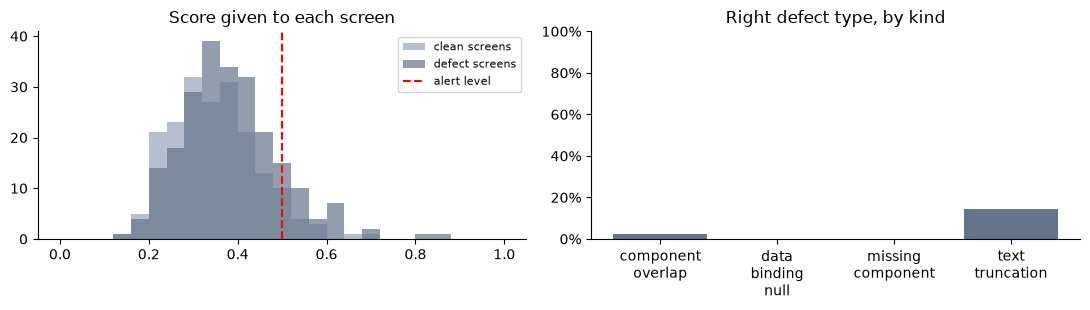

In [2]:
name, color, test_file, e2e_file, thr = MODELS[0]
test, e2e = load(test_file), load(e2e_file)
recs = test['records']
y = np.array([r['gold_has'] is True or str(r['gold_has']).lower() == 'true' for r in recs]); p = np.array([float(r['p_defect']) for r in recs])
flag = p >= thr
found, false_alarm = flag[y].mean(), flag[~y].mean()
s = e2e['summary']
SUMMARY[name] = dict(auc=test['auc'], found=found, false_alarm=false_alarm, type=s['type_accuracy_on_defects'], spot=s['iou_at_0_5_on_defects'])
banner(name, f"Test set: {len(recs)} screens ({y.sum()} with a defect, {(~y).sum()} clean)", color)
cards([('Ranks defects above clean', f"{test['auc']:.2f}"), ('Defects found', f"{found:.0%}"), ('Clean screens wrongly flagged', f"{false_alarm:.0%}"),
       ('Right defect type', f"{s['type_accuracy_on_defects']:.0%}"), ('Right spot (box overlap)', f"{s['iou_at_0_5_on_defects']:.0%}")])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
bins = np.linspace(0, 1, 26)
ax[0].hist(p[~y], bins, alpha=.7, label='clean screens', color='#94a3b8'); ax[0].hist(p[y], bins, alpha=.7, label='defect screens', color=color)
ax[0].axvline(thr, color='red', ls='--', label='alert level'); ax[0].set_title('Score given to each screen'); ax[0].legend(fontsize=8)
pc = s['per_class']; names = list(pc)
ax[1].bar([n.replace('_', '\n') for n in names], [pc[n]['type_correct'] / pc[n]['n'] for n in names], color=color)
ax[1].set_ylim(0, 1); ax[1].set_title('Right defect type, by kind'); ax[1].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

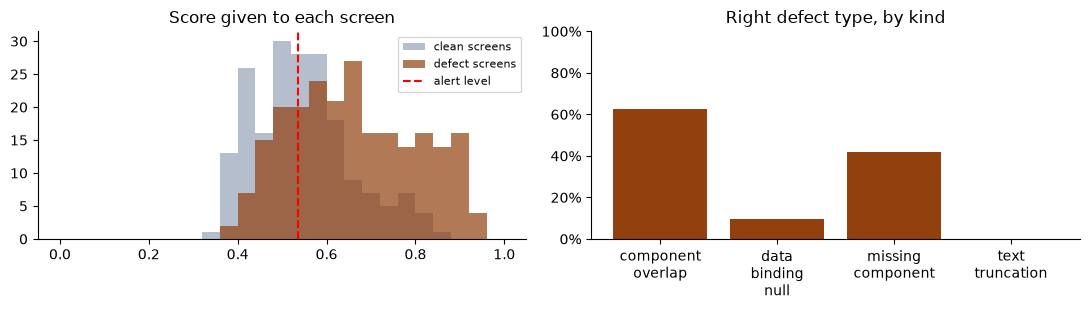

In [3]:
name, color, test_file, e2e_file, thr = MODELS[1]
test, e2e = load(test_file), load(e2e_file)
recs = test['records']
y = np.array([r['gold_has'] is True or str(r['gold_has']).lower() == 'true' for r in recs]); p = np.array([float(r['p_defect']) for r in recs])
flag = p >= thr
found, false_alarm = flag[y].mean(), flag[~y].mean()
s = e2e['summary']
SUMMARY[name] = dict(auc=test['auc'], found=found, false_alarm=false_alarm, type=s['type_accuracy_on_defects'], spot=s['iou_at_0_5_on_defects'])
banner(name, f"Test set: {len(recs)} screens ({y.sum()} with a defect, {(~y).sum()} clean)", color)
cards([('Ranks defects above clean', f"{test['auc']:.2f}"), ('Defects found', f"{found:.0%}"), ('Clean screens wrongly flagged', f"{false_alarm:.0%}"),
       ('Right defect type', f"{s['type_accuracy_on_defects']:.0%}"), ('Right spot (box overlap)', f"{s['iou_at_0_5_on_defects']:.0%}")])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
bins = np.linspace(0, 1, 26)
ax[0].hist(p[~y], bins, alpha=.7, label='clean screens', color='#94a3b8'); ax[0].hist(p[y], bins, alpha=.7, label='defect screens', color=color)
ax[0].axvline(thr, color='red', ls='--', label='alert level'); ax[0].set_title('Score given to each screen'); ax[0].legend(fontsize=8)
pc = s['per_class']; names = list(pc)
ax[1].bar([n.replace('_', '\n') for n in names], [pc[n]['type_correct'] / pc[n]['n'] for n in names], color=color)
ax[1].set_ylim(0, 1); ax[1].set_title('Right defect type, by kind'); ax[1].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

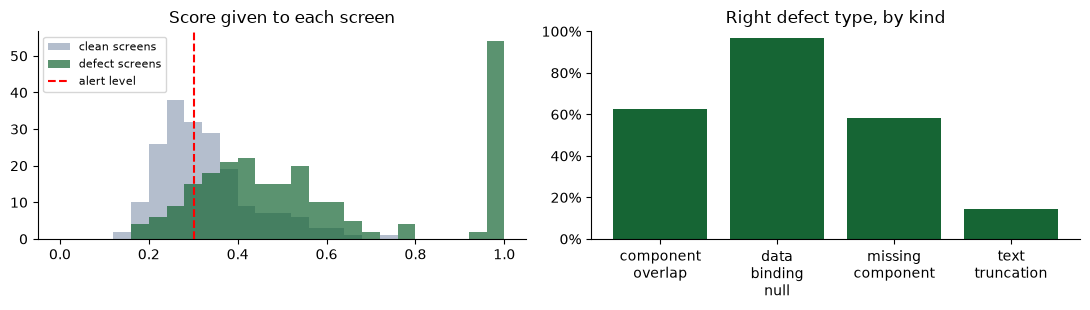

In [4]:
name, color, test_file, e2e_file, thr = MODELS[2]
test, e2e = load(test_file), load(e2e_file)
recs = test['records']
y = np.array([r['gold_has'] is True or str(r['gold_has']).lower() == 'true' for r in recs]); p = np.array([float(r['p_defect']) for r in recs])
flag = p >= thr
found, false_alarm = flag[y].mean(), flag[~y].mean()
s = e2e['summary']
SUMMARY[name] = dict(auc=test['auc'], found=found, false_alarm=false_alarm, type=s['type_accuracy_on_defects'], spot=s['iou_at_0_5_on_defects'])
banner(name, f"Test set: {len(recs)} screens ({y.sum()} with a defect, {(~y).sum()} clean)", color)
cards([('Ranks defects above clean', f"{test['auc']:.2f}"), ('Defects found', f"{found:.0%}"), ('Clean screens wrongly flagged', f"{false_alarm:.0%}"),
       ('Right defect type', f"{s['type_accuracy_on_defects']:.0%}"), ('Right spot (box overlap)', f"{s['iou_at_0_5_on_defects']:.0%}")])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
bins = np.linspace(0, 1, 26)
ax[0].hist(p[~y], bins, alpha=.7, label='clean screens', color='#94a3b8'); ax[0].hist(p[y], bins, alpha=.7, label='defect screens', color=color)
ax[0].axvline(thr, color='red', ls='--', label='alert level'); ax[0].set_title('Score given to each screen'); ax[0].legend(fontsize=8)
pc = s['per_class']; names = list(pc)
ax[1].bar([n.replace('_', '\n') for n in names], [pc[n]['type_correct'] / pc[n]['n'] for n in names], color=color)
ax[1].set_ylim(0, 1); ax[1].set_title('Right defect type, by kind'); ax[1].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

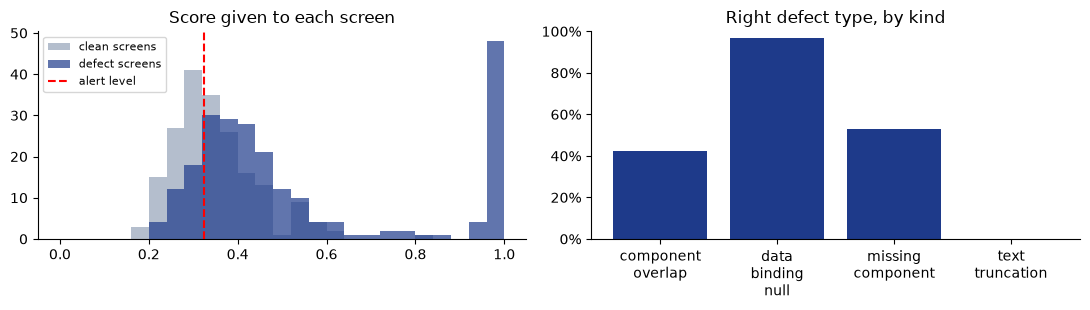

In [5]:
name, color, test_file, e2e_file, thr = MODELS[3]
test, e2e = load(test_file), load(e2e_file)
recs = test['records']
y = np.array([r['gold_has'] is True or str(r['gold_has']).lower() == 'true' for r in recs]); p = np.array([float(r['p_defect']) for r in recs])
flag = p >= thr
found, false_alarm = flag[y].mean(), flag[~y].mean()
s = e2e['summary']
SUMMARY[name] = dict(auc=test['auc'], found=found, false_alarm=false_alarm, type=s['type_accuracy_on_defects'], spot=s['iou_at_0_5_on_defects'])
banner(name, f"Test set: {len(recs)} screens ({y.sum()} with a defect, {(~y).sum()} clean)", color)
cards([('Ranks defects above clean', f"{test['auc']:.2f}"), ('Defects found', f"{found:.0%}"), ('Clean screens wrongly flagged', f"{false_alarm:.0%}"),
       ('Right defect type', f"{s['type_accuracy_on_defects']:.0%}"), ('Right spot (box overlap)', f"{s['iou_at_0_5_on_defects']:.0%}")])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
bins = np.linspace(0, 1, 26)
ax[0].hist(p[~y], bins, alpha=.7, label='clean screens', color='#94a3b8'); ax[0].hist(p[y], bins, alpha=.7, label='defect screens', color=color)
ax[0].axvline(thr, color='red', ls='--', label='alert level'); ax[0].set_title('Score given to each screen'); ax[0].legend(fontsize=8)
pc = s['per_class']; names = list(pc)
ax[1].bar([n.replace('_', '\n') for n in names], [pc[n]['type_correct'] / pc[n]['n'] for n in names], color=color)
ax[1].set_ylim(0, 1); ax[1].set_title('Right defect type, by kind'); ax[1].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## Side by side

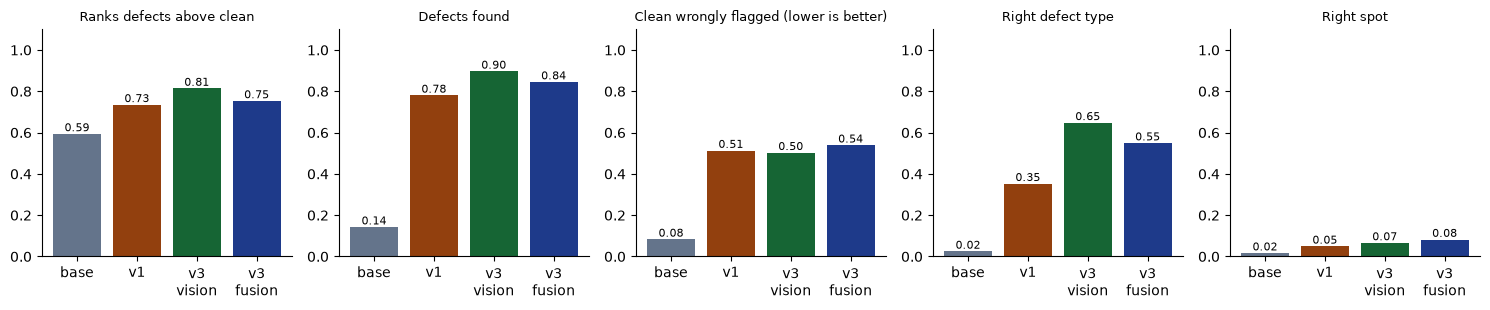

In [6]:
banner('All four together', 'Higher is better for every bar except wrongly flagged clean screens', '#0f172a')
keys = [('auc', 'Ranks defects above clean'), ('found', 'Defects found'), ('false_alarm', 'Clean wrongly flagged (lower is better)'),
        ('type', 'Right defect type'), ('spot', 'Right spot')]
names = list(SUMMARY); cols = [m[1] for m in MODELS]
fig, ax = plt.subplots(1, 5, figsize=(15, 3.2))
for a, (k, t) in zip(ax, keys):
    bars = a.bar(range(len(names)), [SUMMARY[n][k] for n in names], color=cols)
    a.set_xticks(range(len(names))); a.set_xticklabels(['base', 'v1', 'v3\nvision', 'v3\nfusion']); a.set_title(t, fontsize=9)
    a.bar_label(bars, fmt='%.2f', fontsize=8); a.set_ylim(0, 1.1); a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## Take-away
- **v3 vision** ranks defects best (AUC 0.81) and names the right type most often, so it is the shipped model.
- **v3 fusion** needs the layout file as well and did not beat the screenshot-only model here.
- About half of clean screens are still flagged, so a flagged screen is a lead to check, not a proof.
- Finding the exact spot is weak for every model; quote the type and the flag, not the box.